In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

In [8]:
import os

print(os.getcwd())

C:\Users\leena\Documents\personalized-ecommerce-recommender


In [9]:
import pandas as pd

events = pd.read_csv("data/raw/events.csv")

print("Dataset shape:", events.shape)
events.head()

Dataset shape: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [10]:
print("Unique customers:", events["visitorid"].nunique())
print("Unique products:", events["itemid"].nunique())
print("Total interactions:", len(events))

print("\nEvent distribution:")
print(events["event"].value_counts())

print("\nMissing values:")
print(events.isnull().sum())

Unique customers: 1407580
Unique products: 235061
Total interactions: 2756101

Event distribution:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Missing values:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64


In [11]:
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms"
)

events[["timestamp", "datetime"]].head()

,timestamp,datetime
0,1433221332117,2015-06-02 05:02:12.117
1,1433224214164,2015-06-02 05:50:14.164
2,1433221999827,2015-06-02 05:13:19.827
3,1433221955914,2015-06-02 05:12:35.914
4,1433221337106,2015-06-02 05:02:17.106


In [12]:
print("Start date:", events["datetime"].min())
print("End date:", events["datetime"].max())

Start date: 2015-05-03 03:00:04.384000
End date: 2015-09-18 02:59:47.788000


In [13]:
event_counts = events["event"].value_counts()

print(event_counts)

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [14]:
event_percentages = (
    events["event"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(event_percentages)

event
view           96.67
addtocart       2.52
transaction     0.81
Name: proportion, dtype: float64


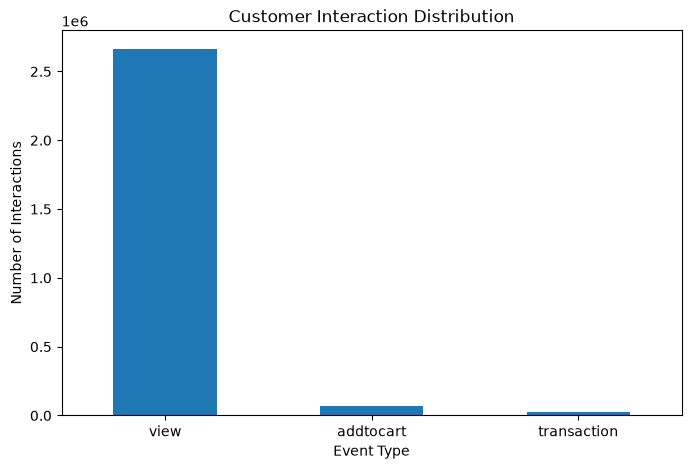

In [15]:
event_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Interaction Distribution")
plt.xlabel("Event Type")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=0)
plt.show()

In [16]:
views = (events["event"] == "view").sum()
carts = (events["event"] == "addtocart").sum()
purchases = (events["event"] == "transaction").sum()

print(f"Views: {views:,}")
print(f"Add to carts: {carts:,}")
print(f"Transactions: {purchases:,}")

print(f"\nCart-to-view ratio: {carts / views * 100:.2f}%")
print(f"Transaction-to-view ratio: {purchases / views * 100:.2f}%")
print(f"Transaction-to-cart ratio: {purchases / carts * 100:.2f}%")

Views: 2,664,312
Add to carts: 69,332
Transactions: 22,457

Cart-to-view ratio: 2.60%
Transaction-to-view ratio: 0.84%
Transaction-to-cart ratio: 32.39%


In [17]:
event_weights = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5
}

events["interaction_score"] = events["event"].map(event_weights)

events[
    ["visitorid", "itemid", "event", "interaction_score"]
].head(20)

,visitorid,itemid,event,interaction_score
0,257597,355908,view,1
1,992329,248676,view,1
2,111016,318965,view,1
3,483717,253185,view,1
4,951259,367447,view,1
5,972639,22556,view,1
6,810725,443030,view,1
7,794181,439202,view,1
8,824915,428805,view,1
9,339335,82389,view,1


In [18]:
print(f"Unique customers: {events['visitorid'].nunique():,}")
print(f"Unique products: {events['itemid'].nunique():,}")
print(f"Total interactions: {len(events):,}")

Unique customers: 1,407,580
Unique products: 235,061
Total interactions: 2,756,101


In [19]:
customer_activity = (
    events.groupby("visitorid")
    .size()
    .sort_values(ascending=False)
)

customer_activity.describe()

count    1.407580e+06
mean     1.958042e+00
std      1.258049e+01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      7.757000e+03
dtype: float64

In [20]:
customer_activity.head(10)

visitorid
1150086    7757
530559     4328
152963     3024
895999     2474
163561     2410
371606     2345
286616     2252
684514     2246
892013     2024
861299     1991
dtype: int64

In [21]:
top_customer = customer_activity.index[0]

print("Customer ID:", top_customer)

customer_journey = (
    events[events["visitorid"] == top_customer]
    .sort_values("datetime")
)

customer_journey[
    ["datetime", "itemid", "event", "interaction_score"]
].head(30)

Customer ID: 1150086


,datetime,itemid,event,interaction_score
230843,2015-06-11 14:55:17.389,133542,view,1
240552,2015-06-11 15:15:35.608,167873,view,1
243885,2015-06-11 15:20:06.651,231726,view,1
229405,2015-06-11 15:24:48.806,427777,view,1
243973,2015-06-11 15:25:32.155,398115,view,1
243884,2015-06-11 15:26:43.191,398115,addtocart,3
237133,2015-06-11 15:28:45.614,398115,transaction,5
229386,2015-06-11 15:29:03.539,398115,view,1
240457,2015-06-11 15:32:07.711,203425,view,1
237227,2015-06-11 15:34:51.672,458489,view,1


In [22]:
top_viewed_products = (
    events[events["event"] == "view"]
    ["itemid"]
    .value_counts()
    .head(10)
)

top_viewed_products

itemid
187946    3410
461686    2539
5411      2325
370653    1854
219512    1740
298009    1642
96924     1633
309778    1565
257040    1531
384302    1528
Name: count, dtype: int64

In [23]:
top_cart_products = (
    events[events["event"] == "addtocart"]
    ["itemid"]
    .value_counts()
    .head(10)
)

top_cart_products

itemid
461686    306
312728    162
409804    156
320130    141
29196     136
7943       97
48030      95
441852     90
445351     89
257040     89
Name: count, dtype: int64

In [24]:
top_purchased_products = (
    events[events["event"] == "transaction"]
    ["itemid"]
    .value_counts()
    .head(10)
)

top_purchased_products

itemid
461686    133
119736     97
213834     92
7943       46
312728     46
445351     45
48030      41
420960     38
248455     38
17478      37
Name: count, dtype: int64

In [25]:
product_scores = (
    events.groupby("itemid")
    .agg(
        total_score=("interaction_score", "sum"),
        interactions=("itemid", "size"),
        unique_customers=("visitorid", "nunique")
    )
    .sort_values("total_score", ascending=False)
)

product_scores.head(10)

,total_score,interactions,unique_customers
itemid,,,
461686,4122,2978,1393
187946,3416,3412,2912
5411,2352,2334,2079
219512,1944,1800,1370
257040,1933,1647,986
320130,1921,1507,886
7943,1867,1489,846
370653,1854,1854,1577
384302,1798,1608,1154


In [26]:
def recommend_popular_products(n=10):
    return product_scores.head(n).reset_index()

In [27]:
recommend_popular_products(10)

,itemid,total_score,interactions,unique_customers
0,461686,4122,2978,1393
1,187946,3416,3412,2912
2,5411,2352,2334,2079
3,219512,1944,1800,1370
4,257040,1933,1647,986
5,320130,1921,1507,886
6,7943,1867,1489,846
7,370653,1854,1854,1577
8,384302,1798,1608,1154
9,309778,1784,1628,1055


In [28]:
processed_events = events[
    [
        "visitorid",
        "itemid",
        "event",
        "interaction_score",
        "datetime"
    ]
].copy()

processed_events.head()

,visitorid,itemid,event,interaction_score,datetime
0,257597,355908,view,1,2015-06-02 05:02:12.117
1,992329,248676,view,1,2015-06-02 05:50:14.164
2,111016,318965,view,1,2015-06-02 05:13:19.827
3,483717,253185,view,1,2015-06-02 05:12:35.914
4,951259,367447,view,1,2015-06-02 05:02:17.106


In [29]:
user_item_interactions = (
    events.groupby(["visitorid", "itemid"])
    ["interaction_score"]
    .sum()
    .reset_index()
)

user_item_interactions.head(10)

,visitorid,itemid,interaction_score
0,0,67045,1
1,0,285930,1
2,0,357564,1
3,1,72028,1
4,2,216305,2
5,2,259884,1
6,2,325215,3
7,2,342816,2
8,3,385090,1
9,4,177677,1


In [30]:
print("Interaction rows:", len(user_item_interactions))
print("Customers:", user_item_interactions["visitorid"].nunique())
print("Products:", user_item_interactions["itemid"].nunique())

Interaction rows: 2145179
Customers: 1407580
Products: 235061


In [31]:
user_activity = (
    user_item_interactions.groupby("visitorid")
    ["itemid"]
    .nunique()
)

item_activity = (
    user_item_interactions.groupby("itemid")
    ["visitorid"]
    .nunique()
)

print("User activity:")
print(user_activity.describe())

print("\nItem activity:")
print(item_activity.describe())

User activity:
count    1.407580e+06
mean     1.524019e+00
std      7.143724e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      3.814000e+03
Name: itemid, dtype: float64

Item activity:
count    235061.000000
mean          9.126052
std          27.102543
min           1.000000
25%           1.000000
50%           2.000000
75%           7.000000
max        2912.000000
Name: visitorid, dtype: float64


In [32]:
print(
    "Users with >= 5 products:",
    (user_activity >= 5).sum()
)

print(
    "Users with >= 10 products:",
    (user_activity >= 10).sum()
)

print(
    "Products with >= 5 users:",
    (item_activity >= 5).sum()
)

print(
    "Products with >= 10 users:",
    (item_activity >= 10).sum()
)

Users with >= 5 products: 39635
Users with >= 10 products: 9446
Products with >= 5 users: 81905
Products with >= 10 users: 47052


In [33]:
active_users = user_activity[user_activity >= 5].index
active_items = item_activity[item_activity >= 5].index

cf_data = user_item_interactions[
    user_item_interactions["visitorid"].isin(active_users)
    &
    user_item_interactions["itemid"].isin(active_items)
].copy()

print("Original interactions:", len(user_item_interactions))
print("Filtered interactions:", len(cf_data))
print("Filtered customers:", cf_data["visitorid"].nunique())
print("Filtered products:", cf_data["itemid"].nunique())

cf_data.head()

Original interactions: 2145179
Filtered interactions: 381434
Filtered customers: 39424
Filtered products: 56188


,visitorid,itemid,interaction_score
65,51,49967,1
66,51,198762,2
67,51,279059,1
69,51,429304,1
72,54,38965,2


In [34]:
from scipy.sparse import csr_matrix

In [35]:
user_ids = cf_data["visitorid"].unique()
item_ids = cf_data["itemid"].unique()

user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

item_to_idx = {
    item_id: idx
    for idx, item_id in enumerate(item_ids)
}

idx_to_user = {
    idx: user_id
    for user_id, idx in user_to_idx.items()
}

idx_to_item = {
    idx: item_id
    for item_id, idx in item_to_idx.items()
}

In [36]:
rows = cf_data["visitorid"].map(user_to_idx)
cols = cf_data["itemid"].map(item_to_idx)
values = cf_data["interaction_score"].astype(float)

user_item_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

print("Matrix shape:", user_item_matrix.shape)
print("Stored interactions:", user_item_matrix.nnz)

Matrix shape: (39424, 56188)
Stored interactions: 381434


In [37]:
from sklearn.neighbors import NearestNeighbors

item_user_matrix = user_item_matrix.T

knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11,
    n_jobs=-1
)

knn_model.fit(item_user_matrix)

print("Collaborative filtering model trained!")

Collaborative filtering model trained!


In [38]:
def get_similar_products(item_id, n=5):
    if item_id not in item_to_idx:
        return []

    item_index = item_to_idx[item_id]

    distances, indices = knn_model.kneighbors(
        item_user_matrix[item_index],
        n_neighbors=n + 1
    )

    recommendations = []

    for distance, index in zip(distances.flatten(), indices.flatten()):
        recommended_item = idx_to_item[index]

        # Exclude the original product
        if recommended_item != item_id:
            recommendations.append({
                "itemid": int(recommended_item),
                "similarity": round(float(1 - distance), 4)
            })

    return recommendations[:n]

In [39]:
get_similar_products(461686, 5)

[{'itemid': 218794, 'similarity': 0.4348},
 {'itemid': 32581, 'similarity': 0.3954},
 {'itemid': 171878, 'similarity': 0.3559},
 {'itemid': 10572, 'similarity': 0.3473},
 {'itemid': 353142, 'similarity': 0.3454}]

In [40]:
def recommend_for_user(visitor_id, n=10):
    user_history = cf_data[
        cf_data["visitorid"] == visitor_id
    ].sort_values(
        "interaction_score",
        ascending=False
    )

    if user_history.empty:
        return recommend_popular_products(n)

    seen_items = set(user_history["itemid"])

    recommendation_scores = {}

    # Use the user's strongest interactions
    for _, row in user_history.head(10).iterrows():

        item_id = row["itemid"]
        user_preference = row["interaction_score"]

        similar_items = get_similar_products(item_id, n=10)

        for rec in similar_items:

            recommended_item = rec["itemid"]

            if recommended_item in seen_items:
                continue

            score = rec["similarity"] * user_preference

            recommendation_scores[recommended_item] = (
                recommendation_scores.get(recommended_item, 0)
                + score
            )

    ranked = sorted(
        recommendation_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return pd.DataFrame(
        ranked[:n],
        columns=["itemid", "recommendation_score"]
    )

In [41]:
test_customer = cf_data["visitorid"].value_counts().index[0]

print("Customer:", test_customer)

Customer: 1150086


In [42]:
cf_data[
    cf_data["visitorid"] == test_customer
].sort_values(
    "interaction_score",
    ascending=False
).head(10)

,visitorid,itemid,interaction_score
1759721,1150086,461686,45
1756941,1150086,119736,44
1758373,1150086,294676,38
1756681,1150086,89323,35
1757997,1150086,248455,32
1757330,1150086,166306,31
1758513,1150086,310944,28
1759112,1150086,384302,28
1756474,1150086,65273,28
1758648,1150086,329133,26


In [43]:
recommend_for_user(test_customer, 10)

,itemid,recommendation_score
0,397981,30.1180
1,249247,29.1632
2,425521,25.9776
3,307074,25.8632
4,442725,25.6080
5,410582,25.3792
6,171878,16.0155
7,75490,15.4644
8,126303,15.3776
9,129327,14.8484


In [44]:
print(user_item_matrix.shape)
print(user_item_matrix.nnz)

get_similar_products(461686, 5)

print("Customer:", test_customer)
recommend_for_user(test_customer, 10)

(39424, 56188)
381434
Customer: 1150086


,itemid,recommendation_score
0,397981,30.1180
1,249247,29.1632
2,425521,25.9776
3,307074,25.8632
4,442725,25.6080
5,410582,25.3792
6,171878,16.0155
7,75490,15.4644
8,126303,15.3776
9,129327,14.8484


In [45]:
positive_events = events[
    events["event"].isin(["addtocart", "transaction"])
].copy()

print("Positive events:", len(positive_events))
print(positive_events["event"].value_counts())

Positive events: 91789
event
addtocart      69332
transaction    22457
Name: count, dtype: int64


In [46]:
positive_user_counts = (
    positive_events.groupby("visitorid")
    ["itemid"]
    .nunique()
)

print("Customers with >= 2 positive products:",
      (positive_user_counts >= 2).sum())

print("Customers with >= 3 positive products:",
      (positive_user_counts >= 3).sum())

print("Customers with >= 5 positive products:",
      (positive_user_counts >= 5).sum())

Customers with >= 2 positive products: 7196
Customers with >= 3 positive products: 3310
Customers with >= 5 positive products: 1302


In [47]:
evaluation_users = positive_user_counts[
    positive_user_counts >= 3
].index

evaluation_events = positive_events[
    positive_events["visitorid"].isin(evaluation_users)
].copy()

evaluation_events = evaluation_events.sort_values(
    ["visitorid", "datetime"]
)

print("Evaluation customers:", len(evaluation_users))
print("Evaluation events:", len(evaluation_events))

evaluation_events[
    ["visitorid", "itemid", "event", "datetime"]
].head(20)

Evaluation customers: 3310
Evaluation events: 37941


,visitorid,itemid,event,datetime
1361435,155,368372,addtocart,2015-09-11 06:12:12.678
1357916,155,452082,addtocart,2015-09-11 06:12:17.583
1368056,155,181405,addtocart,2015-09-11 06:12:47.871
1367869,155,41882,addtocart,2015-09-11 06:17:44.613
1367862,155,442601,addtocart,2015-09-11 06:17:45.950
1364941,155,224623,addtocart,2015-09-11 06:19:00.395
1366578,155,389974,addtocart,2015-09-12 04:38:00.026
445056,420,187848,addtocart,2015-06-23 04:42:03.181
427570,420,178480,addtocart,2015-06-23 04:43:07.674
435505,420,395273,addtocart,2015-06-23 04:44:12.324


In [48]:
customer_history = (
    cf_data[
        cf_data["visitorid"] == test_customer
    ]
    .sort_values(
        "interaction_score",
        ascending=False
    )
)

print("CUSTOMER:", test_customer)

print("\nTOP PRODUCTS ALREADY INTERACTED WITH:")
display(customer_history.head(10))

print("\nPERSONALIZED RECOMMENDATIONS:")
display(recommend_for_user(test_customer, 10))

CUSTOMER: 1150086

TOP PRODUCTS ALREADY INTERACTED WITH:


,visitorid,itemid,interaction_score
1759721,1150086,461686,45
1756941,1150086,119736,44
1758373,1150086,294676,38
1756681,1150086,89323,35
1757997,1150086,248455,32
1757330,1150086,166306,31
1758513,1150086,310944,28
1759112,1150086,384302,28
1756474,1150086,65273,28
1758648,1150086,329133,26



PERSONALIZED RECOMMENDATIONS:


,itemid,recommendation_score
0,397981,30.1180
1,249247,29.1632
2,425521,25.9776
3,307074,25.8632
4,442725,25.6080
5,410582,25.3792
6,171878,16.0155
7,75490,15.4644
8,126303,15.3776
9,129327,14.8484


In [49]:
history_items = set(customer_history["itemid"])

recommendations = recommend_for_user(
    test_customer,
    10
)

recommended_items = set(
    recommendations["itemid"]
)

overlap = history_items.intersection(
    recommended_items
)

print("Already-seen products recommended:", overlap)

Already-seen products recommended: set()


In [50]:
positive_events = events[
    events["event"].isin(["addtocart", "transaction"])
].copy()

positive_user_counts = (
    positive_events.groupby("visitorid")["itemid"]
    .nunique()
)

print("Positive events:", len(positive_events))
print("\nEvent counts:")
print(positive_events["event"].value_counts())

print("\nCustomers with >= 2 positive products:",
      (positive_user_counts >= 2).sum())

print("Customers with >= 3 positive products:",
      (positive_user_counts >= 3).sum())

print("Customers with >= 5 positive products:",
      (positive_user_counts >= 5).sum())

evaluation_users = positive_user_counts[
    positive_user_counts >= 3
].index

evaluation_events = positive_events[
    positive_events["visitorid"].isin(evaluation_users)
].copy()

evaluation_events = evaluation_events.sort_values(
    ["visitorid", "datetime"]
)

print("\nEvaluation customers:", len(evaluation_users))
print("Evaluation events:", len(evaluation_events))

Positive events: 91789

Event counts:
event
addtocart      69332
transaction    22457
Name: count, dtype: int64

Customers with >= 2 positive products: 7196
Customers with >= 3 positive products: 3310
Customers with >= 5 positive products: 1302

Evaluation customers: 3310
Evaluation events: 37941


In [51]:
# Keep the latest positive interaction for each customer-product pair
eval_unique = (
    evaluation_events
    .sort_values("datetime")
    .drop_duplicates(
        subset=["visitorid", "itemid"],
        keep="last"
    )
    .sort_values(["visitorid", "datetime"])
)

# Latest product for each customer becomes the test item
test_data = (
    eval_unique
    .groupby("visitorid")
    .tail(1)
    .copy()
)

# Everything before the latest product becomes training history
train_data = eval_unique.drop(test_data.index).copy()

print("Training interactions:", len(train_data))
print("Test interactions:", len(test_data))
print("Test customers:", test_data["visitorid"].nunique())

Training interactions: 21499
Test interactions: 3310
Test customers: 3310


In [52]:
sample_user = test_data["visitorid"].iloc[0]

print("CUSTOMER:", sample_user)

print("\nTRAINING HISTORY:")
display(
    train_data[
        train_data["visitorid"] == sample_user
    ][["datetime", "itemid", "event"]]
)

print("\nHIDDEN TEST PRODUCT:")
display(
    test_data[
        test_data["visitorid"] == sample_user
    ][["datetime", "itemid", "event"]]
)

CUSTOMER: 155

TRAINING HISTORY:


,datetime,itemid,event
1361435,2015-09-11 06:12:12.678,368372,addtocart
1357916,2015-09-11 06:12:17.583,452082,addtocart
1368056,2015-09-11 06:12:47.871,181405,addtocart
1367869,2015-09-11 06:17:44.613,41882,addtocart
1367862,2015-09-11 06:17:45.950,442601,addtocart
1364941,2015-09-11 06:19:00.395,224623,addtocart



HIDDEN TEST PRODUCT:


,datetime,itemid,event
1366578,2015-09-12 04:38:00.026,389974,addtocart


In [53]:
train_data["interaction_score"] = (
    train_data["event"].map(event_weights)
)

In [54]:
train_interactions = (
    train_data
    .groupby(["visitorid", "itemid"])["interaction_score"]
    .sum()
    .reset_index()
)

print("Training user-item pairs:", len(train_interactions))

train_interactions.head()

Training user-item pairs: 21499


,visitorid,itemid,interaction_score
0,155,41882,3
1,155,181405,3
2,155,224623,3
3,155,368372,3
4,155,442601,3


In [55]:
print(
    "Training customers:",
    train_interactions["visitorid"].nunique()
)

print(
    "Training products:",
    train_interactions["itemid"].nunique()
)

print(
    "Test products:",
    test_data["itemid"].nunique()
)

Training customers: 3310
Training products: 13132
Test products: 2885


In [56]:
training_items = set(train_interactions["itemid"])
test_items = set(test_data["itemid"])

known_test_items = test_items.intersection(training_items)
unknown_test_items = test_items - training_items

print("Unique test products:", len(test_items))
print("Known test products:", len(known_test_items))
print("Cold-start test products:", len(unknown_test_items))

print(
    "Test product coverage:",
    round(
        len(known_test_items) /
        len(test_items) * 100,
        2
    ),
    "%"
)

Unique test products: 2885
Known test products: 1525
Cold-start test products: 1360
Test product coverage: 52.86 %


In [57]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

train_user_ids = train_interactions["visitorid"].unique()
train_item_ids = train_interactions["itemid"].unique()

train_user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(train_user_ids)
}

train_item_to_idx = {
    item_id: idx
    for idx, item_id in enumerate(train_item_ids)
}

train_idx_to_item = {
    idx: item_id
    for item_id, idx in train_item_to_idx.items()
}

In [58]:
train_rows = train_interactions["visitorid"].map(train_user_to_idx)
train_cols = train_interactions["itemid"].map(train_item_to_idx)

train_values = train_interactions[
    "interaction_score"
].astype(float)

train_matrix = csr_matrix(
    (
        train_values,
        (train_rows, train_cols)
    ),
    shape=(
        len(train_user_ids),
        len(train_item_ids)
    )
)

print("Training matrix:", train_matrix.shape)
print("Stored interactions:", train_matrix.nnz)

Training matrix: (3310, 13132)
Stored interactions: 21499


In [59]:
train_item_user_matrix = train_matrix.T

In [60]:
eval_knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=21,
    n_jobs=-1
)

eval_knn_model.fit(train_item_user_matrix)

print("Evaluation KNN model trained.")

Evaluation KNN model trained.


In [61]:
def get_eval_similar_products(item_id, n=20):

    if item_id not in train_item_to_idx:
        return []

    item_index = train_item_to_idx[item_id]

    distances, indices = eval_knn_model.kneighbors(
        train_item_user_matrix[item_index],
        n_neighbors=min(
            n + 1,
            train_item_user_matrix.shape[0]
        )
    )

    recommendations = []

    for distance, index in zip(
        distances.flatten(),
        indices.flatten()
    ):

        recommended_item = train_idx_to_item[index]

        if recommended_item != item_id:

            recommendations.append(
                (
                    int(recommended_item),
                    float(1 - distance)
                )
            )

    return recommendations[:n]

In [62]:
def recommend_eval_user(visitor_id, n=10):

    history = train_interactions[
        train_interactions["visitorid"] == visitor_id
    ]

    if history.empty:
        return []

    seen_items = set(history["itemid"])

    scores = {}

    for _, row in history.iterrows():

        item_id = row["itemid"]
        preference = row["interaction_score"]

        neighbors = get_eval_similar_products(
            item_id,
            n=20
        )

        for recommended_item, similarity in neighbors:

            if recommended_item in seen_items:
                continue

            scores[recommended_item] = (
                scores.get(recommended_item, 0)
                + similarity * preference
            )

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [
        item_id
        for item_id, score in ranked[:n]
    ]

In [63]:
sample_user = test_data["visitorid"].iloc[0]
eligible_test = test_data[
    test_data["itemid"].isin(training_items)
].copy()

print("Eligible test customers:", len(eligible_test))
actual_item = int(
    test_data[
        test_data["visitorid"] == sample_user
    ]["itemid"].iloc[0]
)

recommendations = recommend_eval_user(
    sample_user,
    n=10
)

print("Customer:", sample_user)
print("Actual hidden product:", actual_item)
print("Top-10 recommendations:", recommendations)
print("Hit:", actual_item in recommendations)eligible_test = test_data[
    test_data["itemid"].isin(training_items)
].copy()

print("Eligible test customers:", len(eligible_test))

Customer: 155
Actual hidden product: 389974
Top-10 recommendations: [250640, 166148, 434791, 424912, 280234, 90660, 8651, 1987, 254528, 56238]
Hit: False


In [64]:
eligible_test = test_data[
    test_data["itemid"].isin(training_items)
].copy()

print("Eligible test customers:", len(eligible_test))

Eligible test customers: 1871


In [65]:
hits = 0
evaluated = 0

for _, row in eligible_test.iterrows():

    user_id = row["visitorid"]
    actual_item = row["itemid"]

    recommendations = recommend_eval_user(
        user_id,
        n=10
    )

    if len(recommendations) == 0:
        continue

    evaluated += 1

    if actual_item in recommendations:
        hits += 1

hit_rate_10 = hits / evaluated if evaluated else 0

print("Evaluated customers:", evaluated)
print("Hits:", hits)
print(f"Hit Rate@10: {hit_rate_10:.4f}")

KeyboardInterrupt: 

In [ ]:
precision_scores = []
recall_scores = []

for _, row in eligible_test.iterrows():

    user_id = row["visitorid"]
    actual_item = row["itemid"]

    recommendations = recommend_eval_user(
        user_id,
        n=10
    )

    if not recommendations:
        continue

    hit = int(actual_item in recommendations)

    precision_scores.append(
        hit / len(recommendations)
    )

    recall_scores.append(hit)

In [ ]:
import numpy as np

precision_at_10 = np.mean(precision_scores)
recall_at_10 = np.mean(recall_scores)

print(f"Precision@10: {precision_at_10:.4f}")
print(f"Recall@10: {recall_at_10:.4f}")

In [ ]:
import math

ndcg_scores = []

for _, row in eligible_test.iterrows():

    user_id = row["visitorid"]
    actual_item = row["itemid"]

    recommendations = recommend_eval_user(
        user_id,
        n=10
    )

    if not recommendations:
        continue

    if actual_item in recommendations:

        rank = recommendations.index(actual_item) + 1

        ndcg = 1 / math.log2(rank + 1)

    else:

        ndcg = 0

    ndcg_scores.append(ndcg)

ndcg_at_10 = np.mean(ndcg_scores)

print(f"NDCG@10: {ndcg_at_10:.4f}")

In [ ]:
import numpy as np
import math
import time

hits = 0
evaluated = 0

precision_scores = []
recall_scores = []
ndcg_scores = []

start_time = time.time()

for _, row in eligible_test.iterrows():

    user_id = row["visitorid"]
    actual_item = row["itemid"]

    recommendations = recommend_eval_user(
        user_id,
        n=10
    )

    if not recommendations:
        continue

    evaluated += 1

    if actual_item in recommendations:

        hits += 1

        rank = recommendations.index(actual_item) + 1

        precision_scores.append(
            1 / len(recommendations)
        )

        recall_scores.append(1)

        ndcg_scores.append(
            1 / math.log2(rank + 1)
        )

    else:

        precision_scores.append(0)
        recall_scores.append(0)
        ndcg_scores.append(0)


hit_rate_10 = hits / evaluated

precision_at_10 = np.mean(precision_scores)
recall_at_10 = np.mean(recall_scores)
ndcg_at_10 = np.mean(ndcg_scores)

elapsed = time.time() - start_time


print("\n===== COLLABORATIVE FILTERING RESULTS =====")

print(f"Evaluated customers : {evaluated}")
print(f"Hits                : {hits}")

print(f"Hit Rate@10         : {hit_rate_10:.4f}")
print(f"Precision@10        : {precision_at_10:.4f}")
print(f"Recall@10           : {recall_at_10:.4f}")
print(f"NDCG@10             : {ndcg_at_10:.4f}")

print(f"\nEvaluation time: {elapsed:.2f} seconds")

In [66]:
small_test = eligible_test.head(20)

print("Testing customers:", len(small_test))

Testing customers: 20


In [67]:
import numpy as np
import math
import time

hits = 0
evaluated = 0

precision_scores = []
recall_scores = []
ndcg_scores = []

start_time = time.time()

for i, (_, row) in enumerate(small_test.iterrows(), start=1):

    user_id = row["visitorid"]
    actual_item = row["itemid"]

    print(f"Evaluating customer {i}/20...", end="\r")

    recommendations = recommend_eval_user(
        user_id,
        n=10
    )

    if not recommendations:
        continue

    evaluated += 1

    if actual_item in recommendations:

        hits += 1

        rank = recommendations.index(actual_item) + 1

        precision_scores.append(
            1 / len(recommendations)
        )

        recall_scores.append(1)

        ndcg_scores.append(
            1 / math.log2(rank + 1)
        )

    else:
        precision_scores.append(0)
        recall_scores.append(0)
        ndcg_scores.append(0)

elapsed = time.time() - start_time

print("\n\nFinished!")

print("Evaluated:", evaluated)
print("Hits:", hits)

if evaluated > 0:
    print(f"Hit Rate@10: {hits/evaluated:.4f}")
    print(f"Precision@10: {np.mean(precision_scores):.4f}")
    print(f"Recall@10: {np.mean(recall_scores):.4f}")
    print(f"NDCG@10: {np.mean(ndcg_scores):.4f}")

print(f"Time: {elapsed:.2f} seconds")

Evaluating customer 20/20...

Finished!
Evaluated: 20
Hits: 6
Hit Rate@10: 0.3000
Precision@10: 0.0300
Recall@10: 0.3000
NDCG@10: 0.2224
Time: 4.68 seconds


In [68]:
print("Precomputing product neighbors...")

distances, indices = eval_knn_model.kneighbors(
    train_item_user_matrix,
    n_neighbors=21
)

print("Done!")
print("Distances shape:", distances.shape)
print("Indices shape:", indices.shape)

Precomputing product neighbors...
Done!
Distances shape: (13132, 21)
Indices shape: (13132, 21)


In [69]:
item_neighbors = {}

for item_index in range(len(train_item_ids)):

    original_item = train_idx_to_item[item_index]

    neighbors = []

    for distance, neighbor_index in zip(
        distances[item_index],
        indices[item_index]
    ):
        neighbor_item = train_idx_to_item[neighbor_index]

        if neighbor_item == original_item:
            continue

        similarity = 1 - distance

        neighbors.append(
            (int(neighbor_item), float(similarity))
        )

    item_neighbors[int(original_item)] = neighbors[:20]

print("Cached products:", len(item_neighbors))

Cached products: 13132


In [71]:
def recommend_eval_user_fast(visitor_id, n=10):

    history = train_interactions[
        train_interactions["visitorid"] == visitor_id
    ]

    if history.empty:
        return []

    seen_items = set(history["itemid"])

    scores = {}

    for _, row in history.iterrows():

        item_id = int(row["itemid"])
        preference = row["interaction_score"]

        neighbors = item_neighbors.get(item_id, [])

        for recommended_item, similarity in neighbors:

            if recommended_item in seen_items:
                continue

            scores[recommended_item] = (
                scores.get(recommended_item, 0)
                + similarity * preference
            )

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [
        item_id
        for item_id, score in ranked[:n]
    ]

In [72]:
sample_user = eligible_test["visitorid"].iloc[0]

print("Customer:", sample_user)

print(
    "Recommendations:",
    recommend_eval_user_fast(sample_user, 10)
)

Customer: 420
Recommendations: [395273, 16344, 349470, 319773, 126968, 363783, 132423, 372617, 173365, 153874]


In [73]:
import numpy as np
import math
import time

hits = 0
evaluated = 0

precision_scores = []
recall_scores = []
ndcg_scores = []

start_time = time.time()

total = len(eligible_test)

for i, (_, row) in enumerate(
    eligible_test.iterrows(),
    start=1
):

    user_id = row["visitorid"]
    actual_item = row["itemid"]

    recommendations = recommend_eval_user_fast(
        user_id,
        n=10
    )

    if not recommendations:
        continue

    evaluated += 1

    if actual_item in recommendations:

        hits += 1

        rank = recommendations.index(actual_item) + 1

        precision_scores.append(
            1 / len(recommendations)
        )

        recall_scores.append(1)

        ndcg_scores.append(
            1 / math.log2(rank + 1)
        )

    else:
        precision_scores.append(0)
        recall_scores.append(0)
        ndcg_scores.append(0)

    if i % 250 == 0:
        print(f"Processed {i}/{total}")

elapsed = time.time() - start_time

hit_rate_10 = hits / evaluated
precision_at_10 = np.mean(precision_scores)
recall_at_10 = np.mean(recall_scores)
ndcg_at_10 = np.mean(ndcg_scores)

print("\n===== ITEM-BASED CF RESULTS =====")
print(f"Evaluated customers : {evaluated}")
print(f"Hits                : {hits}")
print(f"Hit Rate@10         : {hit_rate_10:.4f}")
print(f"Precision@10        : {precision_at_10:.4f}")
print(f"Recall@10           : {recall_at_10:.4f}")
print(f"NDCG@10             : {ndcg_at_10:.4f}")
print(f"Evaluation time     : {elapsed:.2f} seconds")

Processed 250/1871
Processed 500/1871
Processed 750/1871
Processed 1000/1871
Processed 1250/1871
Processed 1500/1871
Processed 1750/1871

===== ITEM-BASED CF RESULTS =====
Evaluated customers : 1871
Hits                : 174
Hit Rate@10         : 0.0930
Precision@10        : 0.0093
Recall@10           : 0.0930
NDCG@10             : 0.0619
Evaluation time     : 3.48 seconds


In [74]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [75]:
train_interactions.head()

,visitorid,itemid,interaction_score
0,155,41882,3
1,155,181405,3
2,155,224623,3
3,155,368372,3
4,155,442601,3


In [76]:
print("Training pairs:", len(train_interactions))
print("Users:", train_interactions["visitorid"].nunique())
print("Items:", train_interactions["itemid"].nunique())

Training pairs: 21499
Users: 3310
Items: 13132


In [77]:
ncf_users = train_interactions["visitorid"].unique()
ncf_items = train_interactions["itemid"].unique()

ncf_user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(ncf_users)
}

ncf_item_to_idx = {
    item_id: idx
    for idx, item_id in enumerate(ncf_items)
}

ncf_idx_to_item = {
    idx: item_id
    for item_id, idx in ncf_item_to_idx.items()
}

num_users = len(ncf_users)
num_items = len(ncf_items)

print("NCF users:", num_users)
print("NCF items:", num_items)

NCF users: 3310
NCF items: 13132


In [78]:
positive_pairs = []

for _, row in train_interactions.iterrows():

    user_idx = ncf_user_to_idx[row["visitorid"]]
    item_idx = ncf_item_to_idx[row["itemid"]]

    positive_pairs.append(
        (user_idx, item_idx, 1)
    )

print("Positive samples:", len(positive_pairs))

Positive samples: 21499


In [79]:
user_positive_items = (
    train_interactions
    .groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

In [80]:
import numpy as np

rng = np.random.default_rng(42)

negative_pairs = []

negative_ratio = 4

for _, row in train_interactions.iterrows():

    visitor_id = row["visitorid"]

    user_idx = ncf_user_to_idx[visitor_id]

    positive_item_ids = user_positive_items[visitor_id]

    negatives_added = 0

    while negatives_added < negative_ratio:

        negative_item_idx = rng.integers(
            0,
            num_items
        )

        negative_item_id = ncf_idx_to_item[
            negative_item_idx
        ]

        if negative_item_id not in positive_item_ids:

            negative_pairs.append(
                (
                    user_idx,
                    negative_item_idx,
                    0
                )
            )

            negatives_added += 1

In [81]:
print("Positive samples:", len(positive_pairs))
print("Negative samples:", len(negative_pairs))
print("Total training samples:",
      len(positive_pairs) + len(negative_pairs))

Positive samples: 21499
Negative samples: 85996
Total training samples: 107495


In [82]:
all_samples = positive_pairs + negative_pairs

rng.shuffle(all_samples)

users_array = np.array(
    [x[0] for x in all_samples],
    dtype=np.int32
)

items_array = np.array(
    [x[1] for x in all_samples],
    dtype=np.int32
)

labels_array = np.array(
    [x[2] for x in all_samples],
    dtype=np.float32
)

print(users_array.shape)
print(items_array.shape)
print(labels_array.shape)

print(
    "Positive labels:",
    int(labels_array.sum())
)

(107495,)
(107495,)
(107495,)
Positive labels: 21499


In [83]:
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Flatten,
    Concatenate,
    Dense,
    Dropout
)

In [84]:
embedding_dim = 32

In [85]:
user_input = Input(
    shape=(1,),
    name="user"
)

item_input = Input(
    shape=(1,),
    name="item"
)

In [86]:
user_embedding = Embedding(
    input_dim=num_users,
    output_dim=embedding_dim,
    name="user_embedding"
)(user_input)

user_vector = Flatten()(user_embedding)

In [87]:
item_embedding = Embedding(
    input_dim=num_items,
    output_dim=embedding_dim,
    name="item_embedding"
)(item_input)

item_vector = Flatten()(item_embedding)

In [88]:
x = Concatenate()([
    user_vector,
    item_vector
])

In [89]:
x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.2)(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.2)(x)

x = Dense(
    32,
    activation="relu"
)(x)

In [90]:
output = Dense(
    1,
    activation="sigmoid",
    name="interaction_probability"
)(x)

In [91]:
ncf_model = Model(
    inputs=[
        user_input,
        item_input
    ],
    outputs=output
)

In [92]:
ncf_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [93]:
ncf_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)             │ (None, 1)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ item (InputLayer)             │ (None, 1)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ user_embedding (Embedding)    │ (None, 1, 32)             │         105,920 │ user[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ item_embedding (Embedding)    │ (None, 1, 32)             │         420,224 │ item[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten (Flatten)             │ (None, 32)                │               0 │ user_embedding[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_1 (Flatten)           │ (None, 32)                │               0 │ item_embedding[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 64)                │               0 │ flatten[0][0],             │
│                               │                           │                 │ flatten_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │           8,320 │ concatenate[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 64)                │           8,256 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 64)                │               0 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 32)                │           2,080 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ interaction_probability       │ (None, 1)                 │              33 │ dense_2[0][0]              │
│ (Dense)                       │                           │                 │                            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 544,833 (2.08 MB)

 Trainable params: 544,833 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [94]:
history = ncf_model.fit(
    {
        "user": users_array,
        "item": items_array
    },
    labels_array,
    batch_size=512,
    epochs=5,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.7970 - loss: 0.5224 - val_accuracy: 0.7982 - val_loss: 0.5035
Epoch 2/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8023 - loss: 0.4890 - val_accuracy: 0.8038 - val_loss: 0.4991
Epoch 3/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8088 - loss: 0.4673 - val_accuracy: 0.8016 - val_loss: 0.5450
Epoch 4/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8195 - loss: 0.4193 - val_accuracy: 0.7843 - val_loss: 0.6319
Epoch 5/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8792 - loss: 0.2912 - val_accuracy: 0.7572 - val_loss: 0.8156


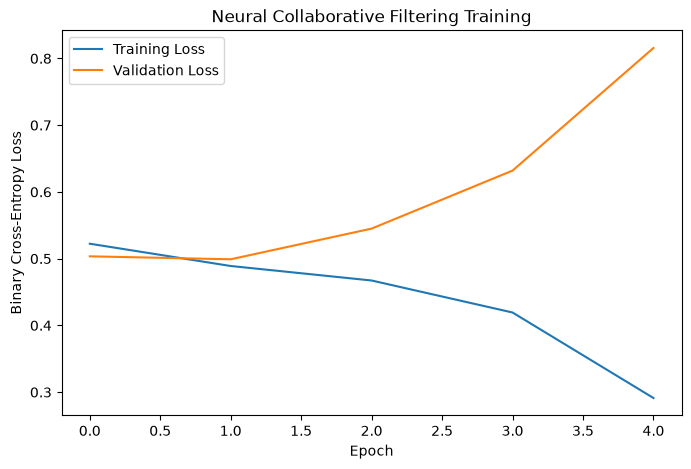

In [95]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Collaborative Filtering Training")
plt.legend()

plt.show()

In [96]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

In [97]:
tf.keras.backend.clear_session()

user_input = Input(shape=(1,), name="user")
item_input = Input(shape=(1,), name="item")

user_embedding = Embedding(
    num_users,
    32,
    name="user_embedding"
)(user_input)

item_embedding = Embedding(
    num_items,
    32,
    name="item_embedding"
)(item_input)

user_vector = Flatten()(user_embedding)
item_vector = Flatten()(item_embedding)

x = Concatenate()([
    user_vector,
    item_vector
])

x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

x = Dense(32, activation="relu")(x)

output = Dense(
    1,
    activation="sigmoid",
    name="interaction_probability"
)(x)

ncf_model = Model(
    inputs=[user_input, item_input],
    outputs=output
)

ncf_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [98]:
history = ncf_model.fit(
    {
        "user": users_array,
        "item": items_array
    },
    labels_array,
    batch_size=512,
    epochs=20,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7987 - loss: 0.5193 - val_accuracy: 0.7982 - val_loss: 0.5043
Epoch 2/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8006 - loss: 0.4913 - val_accuracy: 0.8034 - val_loss: 0.5036
Epoch 3/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8069 - loss: 0.4691 - val_accuracy: 0.7993 - val_loss: 0.5428
Epoch 4/20
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8146 - loss: 0.4355 - val_accuracy: 0.7869 - val_loss: 0.6055
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.


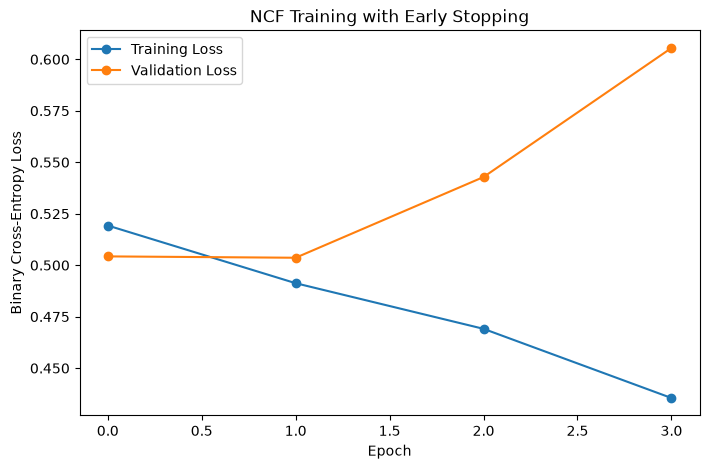

In [99]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("NCF Training with Early Stopping")
plt.legend()
plt.show()

In [100]:
def recommend_ncf_user(visitor_id, n=10):

    if visitor_id not in ncf_user_to_idx:
        return []

    user_idx = ncf_user_to_idx[visitor_id]

    # Products already seen in training
    seen_items = set(
        train_interactions[
            train_interactions["visitorid"] == visitor_id
        ]["itemid"]
    )

    # Candidate products = known training products not already seen
    candidate_item_ids = [
        item_id
        for item_id in ncf_items
        if item_id not in seen_items
    ]

    if not candidate_item_ids:
        return []

    candidate_indices = np.array(
        [
            ncf_item_to_idx[item_id]
            for item_id in candidate_item_ids
        ],
        dtype=np.int32
    )

    user_indices = np.full(
        len(candidate_indices),
        user_idx,
        dtype=np.int32
    )

    predictions = ncf_model.predict(
        {
            "user": user_indices,
            "item": candidate_indices
        },
        batch_size=2048,
        verbose=0
    ).flatten()

    top_indices = np.argsort(predictions)[-n:][::-1]

    return [
        int(candidate_item_ids[i])
        for i in top_indices
    ]

In [101]:
sample_user = eligible_test["visitorid"].iloc[0]

actual_item = int(
    eligible_test[
        eligible_test["visitorid"] == sample_user
    ]["itemid"].iloc[0]
)

ncf_recommendations = recommend_ncf_user(
    sample_user,
    10
)

print("Customer:", sample_user)
print("Actual hidden product:", actual_item)
print("NCF recommendations:", ncf_recommendations)
print("Hit:", actual_item in ncf_recommendations)

Customer: 420
Actual hidden product: 395273
NCF recommendations: [461686, 312728, 409804, 119736, 213834, 234255, 46232, 12217, 10572, 29196]
Hit: False


In [102]:
import time
import math

ncf_small_test = eligible_test.head(20)

hits = 0
ndcg_scores = []

start = time.time()

for i, (_, row) in enumerate(
    ncf_small_test.iterrows(),
    start=1
):

    user_id = row["visitorid"]
    actual_item = int(row["itemid"])

    recommendations = recommend_ncf_user(
        user_id,
        10
    )

    if actual_item in recommendations:

        hits += 1

        rank = recommendations.index(actual_item) + 1

        ndcg_scores.append(
            1 / math.log2(rank + 1)
        )

    else:
        ndcg_scores.append(0)

    print(
        f"Processed {i}/20",
        end="\r"
    )

elapsed = time.time() - start

print("\n")
print("Hits:", hits)
print(f"Hit Rate@10: {hits / 20:.4f}")
print(f"NDCG@10: {np.mean(ndcg_scores):.4f}")
print(f"Time: {elapsed:.2f} seconds")

Processed 20/20

Hits: 1
Hit Rate@10: 0.0500
NDCG@10: 0.0315
Time: 4.69 seconds


In [ ]:
import numpy as np
import math
import time

def evaluate_ncf(model, test_df, k=10):

    hits = 0
    evaluated = 0
    precision_scores = []
    recall_scores = []
    ndcg_scores = []

    start_time = time.time()
    total = len(test_df)

    for i, (_, row) in enumerate(test_df.iterrows(), start=1):

        visitor_id = row["visitorid"]
        actual_item = int(row["itemid"])

        if visitor_id not in ncf_user_to_idx:
            continue

        if actual_item not in ncf_item_to_idx:
            continue

        user_idx = ncf_user_to_idx[visitor_id]

        seen_items = user_positive_items.get(
            visitor_id,
            set()
        )

        # Candidate products
        candidate_ids = [
            item_id
            for item_id in ncf_items
            if item_id not in seen_items
        ]

        candidate_indices = np.array(
            [ncf_item_to_idx[x] for x in candidate_ids],
            dtype=np.int32
        )

        user_indices = np.full(
            len(candidate_indices),
            user_idx,
            dtype=np.int32
        )

        scores = model.predict(
            {
                "user": user_indices,
                "item": candidate_indices
            },
            batch_size=4096,
            verbose=0
        ).flatten()

        # Faster than sorting every item
        if len(scores) > k:

            top_positions = np.argpartition(
                scores,
                -k
            )[-k:]

            top_positions = top_positions[
                np.argsort(scores[top_positions])[::-1]
            ]

        else:
            top_positions = np.argsort(scores)[::-1]

        recommendations = [
            int(candidate_ids[p])
            for p in top_positions
        ]

        evaluated += 1

        if actual_item in recommendations:

            hits += 1

            rank = recommendations.index(actual_item) + 1

            precision_scores.append(
                1 / len(recommendations)
            )

            recall_scores.append(1)

            ndcg_scores.append(
                1 / math.log2(rank + 1)
            )

        else:

            precision_scores.append(0)
            recall_scores.append(0)
            ndcg_scores.append(0)

        if i % 250 == 0:
            print(f"Processed {i}/{total}")

    elapsed = time.time() - start_time

    return {
        "evaluated": evaluated,
        "hits": hits,
        "hit_rate": hits / evaluated,
        "precision": np.mean(precision_scores),
        "recall": np.mean(recall_scores),
        "ndcg": np.mean(ndcg_scores),
        "time": elapsed
    }

In [106]:
ncf_results = evaluate_ncf(
    ncf_model,
    eligible_test,
    k=10
)

Processed 250/1871


KeyboardInterrupt: 

In [ ]:
print("\n===== TENSORFLOW NCF RESULTS =====")

print(
    f"Evaluated customers : {ncf_results['evaluated']}"
)

print(
    f"Hits                : {ncf_results['hits']}"
)

print(
    f"Hit Rate@10         : {ncf_results['hit_rate']:.4f}"
)

print(
    f"Precision@10        : {ncf_results['precision']:.4f}"
)

print(
    f"Recall@10           : {ncf_results['recall']:.4f}"
)

print(
    f"NDCG@10             : {ncf_results['ndcg']:.4f}"
)

print(
    f"Evaluation time     : {ncf_results['time']:.2f} seconds"
)

In [ ]:
print("Users:", num_users)
print("Items:", num_items)

test_prediction = ncf_model.predict(
    {
        "user": np.array([0], dtype=np.int32),
        "item": np.array([0], dtype=np.int32)
    },
    verbose=0
)

print("Test prediction:", test_prediction)

In [107]:
print("Jupyter is working")

Jupyter is working


In [108]:
import sys

print(sys.executable)
print(sys.version)

C:\Users\leena\Documents\personalized-ecommerce-recommender\.venv\Scripts\python.exe
3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


In [109]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

x = tf.constant([1, 2, 3])

print(x)
print(tf.reduce_sum(x))

TensorFlow: 2.21.0
tf.Tensor([1 2 3], shape=(3,), dtype=int32)
tf.Tensor(6, shape=(), dtype=int32)


In [110]:
import sys
import tensorflow as tf

print("Python:")
print(sys.executable)

print("\nTensorFlow:")
print(tf.__version__)

print("\nTensorFlow test:")
print(tf.reduce_sum(tf.constant([1, 2, 3])))

Python:
C:\Users\leena\Documents\personalized-ecommerce-recommender\.venv\Scripts\python.exe

TensorFlow:
2.21.0

TensorFlow test:
tf.Tensor(6, shape=(), dtype=int32)


In [111]:
print(type(ncf_model))

<class 'keras.src.models.functional.Functional'>


In [112]:
ncf_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)             │ (None, 1)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ item (InputLayer)             │ (None, 1)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ user_embedding (Embedding)    │ (None, 1, 32)             │         105,920 │ user[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ item_embedding (Embedding)    │ (None, 1, 32)             │         420,224 │ item[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten (Flatten)             │ (None, 32)                │               0 │ user_embedding[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_1 (Flatten)           │ (None, 32)                │               0 │ item_embedding[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 64)                │               0 │ flatten[0][0],             │
│                               │                           │                 │ flatten_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │           8,320 │ concatenate[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 64)                │           8,256 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 64)                │               0 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 32)                │           2,080 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ interaction_probability       │ (None, 1)                 │              33 │ dense_2[0][0]              │
│ (Dense)                       │                           │                 │                            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 1,634,501 (6.24 MB)

 Trainable params: 544,833 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,089,668 (4.16 MB)

In [113]:
print("Model inputs:", ncf_model.input_names if hasattr(ncf_model, "input_names") else ncf_model.inputs)
print("Model output shape:", ncf_model.output_shape)
print("Number of parameters:", ncf_model.count_params())

Model inputs: [<KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=user>, <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=item>]
Model output shape: (None, 1)
Number of parameters: 544833


In [114]:
print("num_users:", num_users)
print("num_items:", num_items)

print("user mapping size:", len(ncf_user_to_idx))
print("item mapping size:", len(ncf_item_to_idx))

num_users: 3310
num_items: 13132
user mapping size: 3310
item mapping size: 13132


In [115]:
test_user = tf.constant([[0]], dtype=tf.int32)
test_item = tf.constant([[0]], dtype=tf.int32)

print("Before model call")

result = ncf_model(
    {
        "user": test_user,
        "item": test_item
    },
    training=False
)

print("After model call")
print(result)

Before model call
After model call
tf.Tensor([[0.1966044]], shape=(1, 1), dtype=float32)


In [116]:
import numpy as np
import math
import time

test_subset = eligible_test.head(100)

hits = 0
evaluated = 0
ndcg_scores = []

start_time = time.time()

all_item_indices = np.arange(
    num_items,
    dtype=np.int32
).reshape(-1, 1)

print(f"Starting evaluation of {len(test_subset)} customers...")

for i, (_, row) in enumerate(test_subset.iterrows(), start=1):

    visitor_id = row["visitorid"]
    actual_item = int(row["itemid"])

    if visitor_id not in ncf_user_to_idx:
        continue

    if actual_item not in ncf_item_to_idx:
        continue

    user_idx = ncf_user_to_idx[visitor_id]

    user_indices = np.full(
        (num_items, 1),
        user_idx,
        dtype=np.int32
    )

    # Direct TensorFlow call
    scores = ncf_model(
        {
            "user": tf.convert_to_tensor(user_indices),
            "item": tf.convert_to_tensor(all_item_indices)
        },
        training=False
    ).numpy().flatten()

    # Remove already-seen products
    seen_items = user_positive_items.get(visitor_id, set())

    for item_id in seen_items:
        item_index = ncf_item_to_idx.get(item_id)

        if item_index is not None:
            scores[item_index] = -np.inf

    # Top 10
    top_indices = np.argpartition(
        scores,
        -10
    )[-10:]

    top_indices = top_indices[
        np.argsort(scores[top_indices])[::-1]
    ]

    recommendations = [
        int(ncf_idx_to_item[idx])
        for idx in top_indices
    ]

    evaluated += 1

    if actual_item in recommendations:

        hits += 1

        rank = recommendations.index(actual_item) + 1

        ndcg_scores.append(
            1 / math.log2(rank + 1)
        )

    else:
        ndcg_scores.append(0)

    if i % 10 == 0:
        print(f"Processed {i}/100")

elapsed = time.time() - start_time

print("\n===== 100-USER NCF TEST =====")
print("Evaluated:", evaluated)
print("Hits:", hits)

if evaluated > 0:
    print(f"Hit Rate@10: {hits/evaluated:.4f}")
    print(f"Precision@10: {(hits/evaluated)/10:.4f}")
    print(f"Recall@10: {hits/evaluated:.4f}")
    print(f"NDCG@10: {np.mean(ndcg_scores):.4f}")

print(f"Time: {elapsed:.2f} seconds")

Starting evaluation of 100 customers...
Processed 10/100
Processed 20/100
Processed 30/100
Processed 40/100
Processed 50/100
Processed 60/100
Processed 70/100
Processed 80/100
Processed 90/100
Processed 100/100

===== 100-USER NCF TEST =====
Evaluated: 100
Hits: 3
Hit Rate@10: 0.0300
Precision@10: 0.0030
Recall@10: 0.0300
NDCG@10: 0.0135
Time: 6.53 seconds


In [117]:
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()

embedding_dim = 16

user_input = Input(
    shape=(1,),
    name="user"
)

item_input = Input(
    shape=(1,),
    name="item"
)

user_embedding = Embedding(
    input_dim=num_users,
    output_dim=embedding_dim,
    embeddings_regularizer=l2(1e-5),
    name="user_embedding"
)(user_input)

item_embedding = Embedding(
    input_dim=num_items,
    output_dim=embedding_dim,
    embeddings_regularizer=l2(1e-5),
    name="item_embedding"
)(item_input)

user_vector = Flatten()(user_embedding)
item_vector = Flatten()(item_embedding)

x = Concatenate()([
    user_vector,
    item_vector
])

x = Dense(
    64,
    activation="relu",
    kernel_regularizer=l2(1e-5)
)(x)

x = Dropout(0.3)(x)

x = Dense(
    32,
    activation="relu",
    kernel_regularizer=l2(1e-5)
)(x)

x = Dropout(0.2)(x)

output = Dense(
    1,
    activation="sigmoid",
    name="interaction_probability"
)(x)

ncf_model_v2 = Model(
    inputs=[user_input, item_input],
    outputs=output
)

ncf_model_v2.compile(
    optimizer=Adam(
        learning_rate=0.0005
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ncf_model_v2.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)             │ (None, 1)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ item (InputLayer)             │ (None, 1)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ user_embedding (Embedding)    │ (None, 1, 16)             │          52,960 │ user[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ item_embedding (Embedding)    │ (None, 1, 16)             │         210,112 │ item[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten (Flatten)             │ (None, 16)                │               0 │ user_embedding[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_1 (Flatten)           │ (None, 16)                │               0 │ item_embedding[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 32)                │               0 │ flatten[0][0],             │
│                               │                           │                 │ flatten_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 64)                │           2,112 │ concatenate[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 64)                │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 32)                │           2,080 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 32)                │               0 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ interaction_probability       │ (None, 1)                 │              33 │ dropout_1[0][0]            │
│ (Dense)                       │                           │                 │                            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 267,297 (1.02 MB)

 Trainable params: 267,297 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [118]:
early_stopping_v2 = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

history_v2 = ncf_model_v2.fit(
    {
        "user": users_array,
        "item": items_array
    },
    labels_array,
    batch_size=512,
    epochs=15,
    validation_split=0.1,
    callbacks=[early_stopping_v2],
    verbose=1
)

Epoch 1/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7921 - loss: 0.5672 - val_accuracy: 0.7982 - val_loss: 0.5087
Epoch 2/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8002 - loss: 0.5017 - val_accuracy: 0.7982 - val_loss: 0.5165
Epoch 3/15
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8005 - loss: 0.4834 - val_accuracy: 0.8012 - val_loss: 0.5393
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


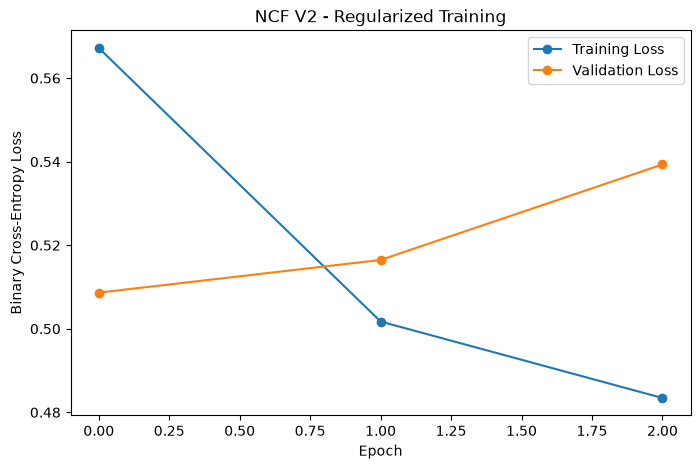

In [119]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_v2.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("NCF V2 - Regularized Training")
plt.legend()

plt.show()

In [120]:
import numpy as np
import math
import time

test_subset = eligible_test.head(100)

hits = 0
evaluated = 0
ndcg_scores = []

start_time = time.time()

all_item_indices = np.arange(
    num_items,
    dtype=np.int32
).reshape(-1, 1)

print(f"Starting NCF V2 evaluation of {len(test_subset)} customers...")

for i, (_, row) in enumerate(test_subset.iterrows(), start=1):

    visitor_id = row["visitorid"]
    actual_item = int(row["itemid"])

    if visitor_id not in ncf_user_to_idx:
        continue

    if actual_item not in ncf_item_to_idx:
        continue

    user_idx = ncf_user_to_idx[visitor_id]

    user_indices = np.full(
        (num_items, 1),
        user_idx,
        dtype=np.int32
    )

    scores = ncf_model_v2(
        {
            "user": tf.convert_to_tensor(user_indices),
            "item": tf.convert_to_tensor(all_item_indices)
        },
        training=False
    ).numpy().flatten()

    # Exclude products already seen in training
    seen_items = user_positive_items.get(visitor_id, set())

    for item_id in seen_items:
        item_index = ncf_item_to_idx.get(item_id)

        if item_index is not None:
            scores[item_index] = -np.inf

    # Top 10 recommendations
    top_indices = np.argpartition(scores, -10)[-10:]

    top_indices = top_indices[
        np.argsort(scores[top_indices])[::-1]
    ]

    recommendations = [
        int(ncf_idx_to_item[idx])
        for idx in top_indices
    ]

    evaluated += 1

    if actual_item in recommendations:

        hits += 1

        rank = recommendations.index(actual_item) + 1

        ndcg_scores.append(
            1 / math.log2(rank + 1)
        )

    else:
        ndcg_scores.append(0)

    if i % 10 == 0:
        print(f"Processed {i}/100")

elapsed = time.time() - start_time

print("\n===== NCF V2 - 100 USER TEST =====")
print("Evaluated:", evaluated)
print("Hits:", hits)

if evaluated > 0:
    hr = hits / evaluated

    print(f"Hit Rate@10: {hr:.4f}")
    print(f"Precision@10: {hr/10:.4f}")
    print(f"Recall@10: {hr:.4f}")
    print(f"NDCG@10: {np.mean(ndcg_scores):.4f}")

print(f"Time: {elapsed:.2f} seconds")

Starting NCF V2 evaluation of 100 customers...
Processed 10/100
Processed 20/100
Processed 30/100
Processed 40/100
Processed 50/100
Processed 60/100
Processed 70/100
Processed 80/100
Processed 90/100
Processed 100/100

===== NCF V2 - 100 USER TEST =====
Evaluated: 100
Hits: 3
Hit Rate@10: 0.0300
Precision@10: 0.0030
Recall@10: 0.0300
NDCG@10: 0.0100
Time: 3.07 seconds


In [121]:
item_cf_metrics = {
    "model": "Item-Based Collaborative Filtering",
    "evaluated_customers": 1871,
    "hits": 174,
    "hit_rate_at_10": 0.0930,
    "precision_at_10": 0.0093,
    "recall_at_10": 0.0930,
    "ndcg_at_10": 0.0619
}

item_cf_metrics

{'model': 'Item-Based Collaborative Filtering',
 'evaluated_customers': 1871,
 'hits': 174,
 'hit_rate_at_10': 0.093,
 'precision_at_10': 0.0093,
 'recall_at_10': 0.093,
 'ndcg_at_10': 0.0619}

In [122]:
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Item-CF",
        "Evaluation Users": 1871,
        "HR@10": 0.0930,
        "Precision@10": 0.0093,
        "Recall@10": 0.0930,
        "NDCG@10": 0.0619,
        "Status": "Champion"
    },
    {
        "Model": "NCF V1",
        "Evaluation Users": 100,
        "HR@10": 0.0300,
        "Precision@10": 0.0030,
        "Recall@10": 0.0300,
        "NDCG@10": 0.0135,
        "Status": "Experimental"
    },
    {
        "Model": "NCF V2",
        "Evaluation Users": 100,
        "HR@10": 0.0300,
        "Precision@10": 0.0030,
        "Recall@10": 0.0300,
        "NDCG@10": 0.0100,
        "Status": "Experimental"
    }
])

model_comparison

,Model,Evaluation Users,HR@10,Precision@10,Recall@10,NDCG@10,Status
0,Item-CF,1871,0.093,0.0093,0.093,0.0619,Champion
1,NCF V1,100,0.030,0.0030,0.030,0.0135,Experimental
2,NCF V2,100,0.030,0.0030,0.030,0.0100,Experimental


In [123]:
import mlflow
import mlflow.tensorflow
import pandas as pd

print("MLflow version:", mlflow.__version__)

MLflow version: 3.17.0


In [124]:
mlflow.set_experiment(
    "personalized-ecommerce-recommender"
)

print("MLflow experiment configured.")

C:\Users\leena\Documents\personalized-ecommerce-recommender\.venv\Lib\site-packages\mlflow\store\tracking\sqlalchemy_store.py:327: SADeprecationWarning: The ``noload`` loader strategy is deprecated and will be removed in a future release.  This option produces incorrect results by returning ``None`` for related items. (deprecated since: 2.1)
  sqlalchemy.orm.configure_mappers()
2026/10/07 17:56:49 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/07 17:56:49 INFO mlflow.store.db.utils: Updating database tables
2026/10/07 17:56:53 INFO mlflow.tracking.fluent: Experiment with name 'personalized-ecommerce-recommender' does not exist. Creating a new experiment.


MLflow experiment configured.


In [125]:
with mlflow.start_run(run_name="item_cf_champion"):

    # Model parameters
    mlflow.log_param("model_type", "Item-Based Collaborative Filtering")
    mlflow.log_param("similarity_metric", "cosine")
    mlflow.log_param("algorithm", "brute")
    mlflow.log_param("top_k", 10)
    mlflow.log_param("min_user_interactions", 5)
    mlflow.log_param("min_item_interactions", 5)
    mlflow.log_param("evaluation_method", "temporal_leave_last_out")

    # Dataset information
    mlflow.log_param("dataset", "Retailrocket")
    mlflow.log_param("implicit_feedback", True)

    # Final metrics
    mlflow.log_metric("evaluated_customers", 1871)
    mlflow.log_metric("hits", 174)
    mlflow.log_metric("hit_rate_at_10", 0.0930)
    mlflow.log_metric("precision_at_10", 0.0093)
    mlflow.log_metric("recall_at_10", 0.0930)
    mlflow.log_metric("ndcg_at_10", 0.0619)

    # Helpful tags
    mlflow.set_tag("model_status", "champion")
    mlflow.set_tag(
        "description",
        "Item-based collaborative filtering baseline using cosine similarity."
    )

print("Item-CF experiment logged successfully.")

Item-CF experiment logged successfully.


In [126]:
with mlflow.start_run(run_name="ncf_v1_experimental"):

    mlflow.log_param("model_type", "Neural Collaborative Filtering")
    mlflow.log_param("embedding_dim", 32)
    mlflow.log_param("negative_sampling_ratio", 4)
    mlflow.log_param("optimizer", "Adam")
    mlflow.log_param("evaluation_scope", "100_user_diagnostic")

    mlflow.log_metric("evaluated_customers", 100)
    mlflow.log_metric("hits", 3)
    mlflow.log_metric("hit_rate_at_10", 0.0300)
    mlflow.log_metric("precision_at_10", 0.0030)
    mlflow.log_metric("recall_at_10", 0.0300)
    mlflow.log_metric("ndcg_at_10", 0.0135)

    mlflow.set_tag("model_status", "experimental")


with mlflow.start_run(run_name="ncf_v2_regularized"):

    mlflow.log_param("model_type", "Neural Collaborative Filtering")
    mlflow.log_param("embedding_dim", 16)
    mlflow.log_param("negative_sampling_ratio", 4)
    mlflow.log_param("learning_rate", 0.0005)
    mlflow.log_param("early_stopping", True)
    mlflow.log_param("evaluation_scope", "100_user_diagnostic")

    mlflow.log_metric("evaluated_customers", 100)
    mlflow.log_metric("hits", 3)
    mlflow.log_metric("hit_rate_at_10", 0.0300)
    mlflow.log_metric("precision_at_10", 0.0030)
    mlflow.log_metric("recall_at_10", 0.0300)
    mlflow.log_metric("ndcg_at_10", 0.0100)

    mlflow.set_tag("model_status", "experimental")

print("NCF experiments logged successfully.")

NCF experiments logged successfully.


In [127]:
import mlflow
import mlflow.tensorflow
import pandas as pd

print("MLflow version:", mlflow.__version__)


MLflow version: 3.17.0


In [128]:
mlflow.set_experiment(
    "personalized-ecommerce-recommender"
)

print("MLflow experiment configured.")

MLflow experiment configured.


In [129]:
with mlflow.start_run(run_name="item_cf_champion"):

    # Model parameters
    mlflow.log_param("model_type", "Item-Based Collaborative Filtering")
    mlflow.log_param("similarity_metric", "cosine")
    mlflow.log_param("algorithm", "brute")
    mlflow.log_param("top_k", 10)
    mlflow.log_param("min_user_interactions", 5)
    mlflow.log_param("min_item_interactions", 5)
    mlflow.log_param("evaluation_method", "temporal_leave_last_out")

    # Dataset information
    mlflow.log_param("dataset", "Retailrocket")
    mlflow.log_param("implicit_feedback", True)

    # Final metrics
    mlflow.log_metric("evaluated_customers", 1871)
    mlflow.log_metric("hits", 174)
    mlflow.log_metric("hit_rate_at_10", 0.0930)
    mlflow.log_metric("precision_at_10", 0.0093)
    mlflow.log_metric("recall_at_10", 0.0930)
    mlflow.log_metric("ndcg_at_10", 0.0619)

    # Helpful tags
    mlflow.set_tag("model_status", "champion")
    mlflow.set_tag(
        "description",
        "Item-based collaborative filtering baseline using cosine similarity."
    )

print("Item-CF experiment logged successfully.")

Item-CF experiment logged successfully.


In [130]:
with mlflow.start_run(run_name="ncf_v1_experimental"):

    mlflow.log_param("model_type", "Neural Collaborative Filtering")
    mlflow.log_param("embedding_dim", 32)
    mlflow.log_param("negative_sampling_ratio", 4)
    mlflow.log_param("optimizer", "Adam")
    mlflow.log_param("evaluation_scope", "100_user_diagnostic")

    mlflow.log_metric("evaluated_customers", 100)
    mlflow.log_metric("hits", 3)
    mlflow.log_metric("hit_rate_at_10", 0.0300)
    mlflow.log_metric("precision_at_10", 0.0030)
    mlflow.log_metric("recall_at_10", 0.0300)
    mlflow.log_metric("ndcg_at_10", 0.0135)

    mlflow.set_tag("model_status", "experimental")


with mlflow.start_run(run_name="ncf_v2_regularized"):

    mlflow.log_param("model_type", "Neural Collaborative Filtering")
    mlflow.log_param("embedding_dim", 16)
    mlflow.log_param("negative_sampling_ratio", 4)
    mlflow.log_param("learning_rate", 0.0005)
    mlflow.log_param("early_stopping", True)
    mlflow.log_param("evaluation_scope", "100_user_diagnostic")

    mlflow.log_metric("evaluated_customers", 100)
    mlflow.log_metric("hits", 3)
    mlflow.log_metric("hit_rate_at_10", 0.0300)
    mlflow.log_metric("precision_at_10", 0.0030)
    mlflow.log_metric("recall_at_10", 0.0300)
    mlflow.log_metric("ndcg_at_10", 0.0100)

    mlflow.set_tag("model_status", "experimental")

print("NCF experiments logged successfully.")

NCF experiments logged successfully.


In [131]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

print(MODEL_DIR.resolve())

C:\Users\leena\Documents\personalized-ecommerce-recommender\models


In [132]:
import pickle

with open(MODEL_DIR / "item_cf_model.pkl", "wb") as f:
    pickle.dump(knn_model, f)

with open(MODEL_DIR / "user_item_matrix.pkl", "wb") as f:
    pickle.dump(user_item_matrix, f)

with open(MODEL_DIR / "user_to_idx.pkl", "wb") as f:
    pickle.dump(user_to_idx, f)

with open(MODEL_DIR / "item_to_idx.pkl", "wb") as f:
    pickle.dump(item_to_idx, f)

with open(MODEL_DIR / "idx_to_item.pkl", "wb") as f:
    pickle.dump(idx_to_item, f)

print("Item-CF artifacts saved.")

Item-CF artifacts saved.


In [133]:
for file in MODEL_DIR.iterdir():
    print(
        file.name,
        f"{file.stat().st_size / (1024 * 1024):.2f} MB"
    )

idx_to_item.pkl 1.18 MB
item_cf_model.pkl 4.58 MB
item_to_idx.pkl 1.18 MB
user_item_matrix.pkl 4.52 MB
user_to_idx.pkl 0.83 MB


In [134]:
with open(MODEL_DIR / "item_cf_model.pkl", "rb") as f:
    loaded_knn_model = pickle.load(f)

with open(MODEL_DIR / "user_item_matrix.pkl", "rb") as f:
    loaded_user_item_matrix = pickle.load(f)

with open(MODEL_DIR / "user_to_idx.pkl", "rb") as f:
    loaded_user_to_idx = pickle.load(f)

with open(MODEL_DIR / "item_to_idx.pkl", "rb") as f:
    loaded_item_to_idx = pickle.load(f)

with open(MODEL_DIR / "idx_to_item.pkl", "rb") as f:
    loaded_idx_to_item = pickle.load(f)

print("Model loaded successfully.")
print("Matrix shape:", loaded_user_item_matrix.shape)
print("Customers:", len(loaded_user_to_idx))
print("Products:", len(loaded_item_to_idx))

Model loaded successfully.
Matrix shape: (39424, 56188)
Customers: 39424
Products: 56188


In [135]:
from fastapi import FastAPI, HTTPException, Query

from src.models.recommender import ItemCFRecommender


app = FastAPI(
    title="Personalized E-Commerce Recommendation API",
    description=(
        "Item-based collaborative filtering API for "
        "personalized product recommendations."
    ),
    version="1.0.0"
)

# Load model once when the API starts
recommender = ItemCFRecommender()


@app.get("/")
def root():
    return {
        "message": "Personalized E-Commerce Recommendation API",
        "status": "running"
    }


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model": "Item-Based Collaborative Filtering",
        "customers": len(recommender.user_to_idx),
        "products": len(recommender.item_to_idx)
    }


@app.get("/recommend/{visitor_id}")
def recommend(
    visitor_id: int,
    n: int = Query(default=10, ge=1, le=50)
):
    recommendations = recommender.recommend(
        visitor_id=visitor_id,
        n=n
    )

    if not recommendations:
        raise HTTPException(
            status_code=404,
            detail="Customer not found or no recommendations available."
        )

    return {
        "visitor_id": visitor_id,
        "model": "item_cf",
        "count": len(recommendations),
        "recommendations": recommendations
    }